
# Handwritten Digit Recognition Using Convolutional Neural Networks

## A Comparative Study of LeCun (1989) and Chollet (2021)

**Module:** Computer Vision  
**Dataset:** MNIST Handwritten Digits  
**Models:** LeCun-inspired CNN and Chollet CNN  
**Framework:** TensorFlow / Keras

---

## 1. Introduction

Handwritten digit recognition is a fundamental image classification problem in computer vision. The objective is to develop a computational model capable of identifying handwritten numerical digits from images and assigning each image to one of ten classes, representing the digits zero through nine.

Convolutional Neural Networks (CNNs) have become particularly effective for image recognition because they can automatically learn spatial features from image data. Unlike traditional machine learning approaches that often depend on manually engineered features, CNNs use convolutional filters to identify patterns such as edges, curves and more complex visual structures.

LeCun et al. (1989), in their work *Backpropagation Applied to Handwritten Zip Code Recognition*, demonstrated the effectiveness of convolutional neural networks for recognising handwritten digits. Their approach introduced important architectural principles, including local receptive fields, shared weights and subsampling.

This practical investigates these principles by implementing a LeCun-inspired convolutional neural network using modern TensorFlow/Keras functionality. Its performance is compared with the conventional MNIST CNN implementation presented by François Chollet (2021).

The experiment uses the MNIST dataset, which contains grayscale images of handwritten digits. Both networks are trained and evaluated using a consistent experimental protocol to investigate their classification performance and computational requirements.

### 1.1 Aim

The aim of this practical is to implement and evaluate a historical LeCun-inspired convolutional neural network for handwritten digit recognition and compare its performance with the Chollet (2021) Keras implementation.

### 1.2 Objectives

The objectives are to:

1. Describe and explore the MNIST handwritten digit dataset.
2. Implement a CNN based on the architectural principles of LeCun et al. (1989).
3. Explain and justify the modifications required to adapt the historical architecture to modern Keras and the MNIST dataset.
4. Implement the Chollet (2021) CNN as a comparison baseline.
5. Compare the architectures, preprocessing methods, training configurations and trainable parameters.
6. Train and evaluate both networks using multiple independent runs.
7. Compare test loss, test accuracy and training duration.
8. Analyse classification errors using confusion matrices and misclassified examples.

### 1.3 Research question

How does a LeCun-inspired convolutional neural network compare with the Chollet (2021) CNN implementation in recognising handwritten digits from the MNIST dataset?

### 1.4 References

- LeCun, Y., Boser, B., Denker, J. S., Henderson, D., Howard, R. E., Hubbard, W. and Jackel, L. D. (1989). Backpropagation Applied to Handwritten Zip Code Recognition. *Neural Computation*, 1(4), 541–551.
- Chollet, F. (2021). *Deep Learning with Python*. 2nd ed. Manning Publications.

## 2. MNIST Dataset

The Modified National Institute of Standards and Technology (MNIST) dataset is a widely used benchmark for handwritten digit classification. It consists of 70,000 grayscale images representing the digits zero through nine.

Each image has a resolution of 28 × 28 pixels, with pixel intensity values ranging from 0 to 255. The dataset is divided into 60,000 training images and 10,000 test images.

The classification task involves assigning each image to one of ten possible classes. The dataset provides a consistent benchmark for evaluating image classification models and allows the performance of different CNN architectures to be compared.

### 2.1 Dataset characteristics

The following characteristics are relevant to this practical:

- **Total images:** 70,000
- **Training images:** 60,000
- **Test images:** 10,000
- **Image dimensions:** 28 × 28 pixels
- **Colour channels:** 1 (grayscale)
- **Number of classes:** 10
- **Class labels:** Digits 0–9

In the following section, the dataset will be loaded and explored to verify its dimensions, examine the distribution of digit classes and visualise representative handwritten digit images.

In [3]:
"""Load the MNIST dataset and inspect its structure."""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Load the MNIST dataset from Keras.
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

# Display dataset dimensions.
print("MNIST Dataset Overview")
print("-" * 40)
print(f"Training images: {x_train.shape}")
print(f"Training labels: {y_train.shape}")
print(f"Test images:     {x_test.shape}")
print(f"Test labels:     {y_test.shape}")

# Display image properties.
print("\nImage Properties")
print("-" * 40)
print(f"Image dimensions:  {x_train.shape[1]} × {x_train.shape[2]}")
print(f"Pixel data type:   {x_train.dtype}")
print(f"Minimum pixel:     {x_train.min()}")
print(f"Maximum pixel:     {x_train.max()}")
print(f"Number of classes: {len(np.unique(y_train))}")

MNIST Dataset Overview
----------------------------------------
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images:     (10000, 28, 28)
Test labels:     (10000,)

Image Properties
----------------------------------------
Image dimensions:  28 × 28
Pixel data type:   uint8
Minimum pixel:     0
Maximum pixel:     255
Number of classes: 10


Digit Class Distribution
----------------------------------------
Digit     Training       Test           
0         5923           980            
1         6742           1135           
2         5958           1032           
3         6131           1010           
4         5842           982            
5         5421           892            
6         5918           958            
7         6265           1028           
8         5851           974            
9         5949           1009           


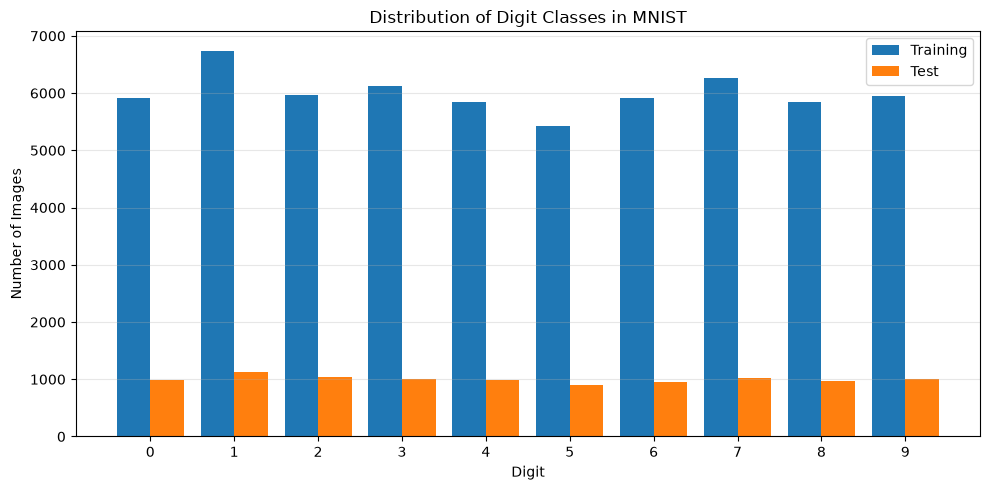

In [5]:
"""Examine the distribution of digit classes in MNIST."""

# Count occurrences of each digit.
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

# Display class distribution.
print("Digit Class Distribution")
print("-" * 40)
print(f"{'Digit':<10}{'Training':<15}{'Test':<15}")

for digit in range(10):
    print(f"{digit:<10}{train_counts[digit]:<15}{test_counts[digit]:<15}")

# Visualise the training and test distributions.
digits = np.arange(10)
width = 0.4

plt.figure(figsize=(10, 5))
plt.bar(digits - width / 2, train_counts, width, label="Training")
plt.bar(digits + width / 2, test_counts, width, label="Test")

plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.title("Distribution of Digit Classes in MNIST")
plt.xticks(digits)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.2 Interpretation of Class Distribution

The class distribution shows that all ten digit classes are represented in both the training and test datasets. However, the number of images is not exactly equal across the classes.

In the training dataset, digit 1 has the highest representation, with 6,742 images, while digit 5 has the lowest representation, with 5,421 images. A similar pattern is observed in the test dataset, where digit 1 has 1,135 images and digit 5 has 892 images.

Despite these differences, the distribution is reasonably balanced, as no individual class overwhelmingly dominates the dataset. The training and test distributions also show similar patterns, which provides a consistent basis for model training and evaluation.

The class distribution is important because substantial differences in the number of examples per class could influence a model's learning behaviour and classification performance. Although MNIST is not perfectly balanced, the observed distribution does not indicate a severe class imbalance.

Therefore, all ten classes can be retained for the experiments without requiring additional class-balancing techniques.

### 2.3 Visual Inspection of Handwritten Digits

A visual inspection of sample images helps illustrate the characteristics of the MNIST dataset and the variation in handwriting across the ten digit classes.

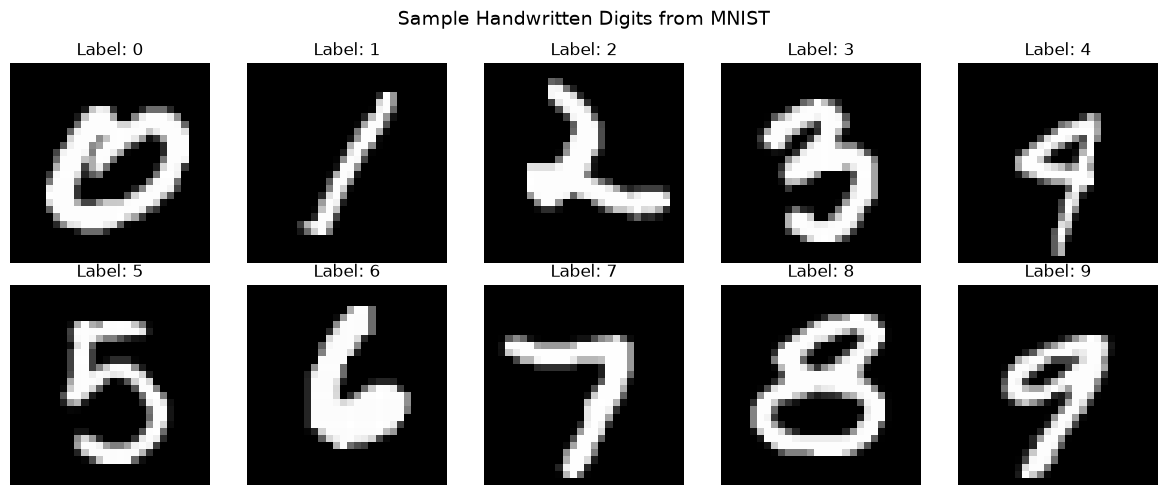

In [6]:
"""Visulaise sample handwritten digits from the MNIST training dataset."""

# Select one reproducible random example from each of digit class.
rng = np.random.default_rng(42)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in enumerate(axes.flat):
    # Find all training images belonging to the current digit.
    digit_indices = np.where(y_train == digit)[0]

    # Select one image at random.
    image_index = rng.choice(digit_indices)

    # Display the image and its label.
    ax.imshow(x_train[image_index], cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")

plt.suptitle("Sample Handwritten Digits from MNIST", fontsize=14)
plt.tight_layout()
plt.show()